# m04 - Spatial-Context Features and Training at the Source Resolution

A GAEZ pixel value summarises roughly 80 one-kilometre cells, so the point value of a feature at a single cell is the
wrong support for that target. Two ways to give the model the right spatial context:

1. **Focal means**: average every input over k x k neighbourhoods on the 1 km grid (k = 3 ... 41 km).
2. **Pixel means**: average every input over the native GAEZ pixel the cell belongs to.

Then the opposite route: **train at the source resolution** (164 rows, one per native pixel) and compare it with the
cell-level models after aggregating their predictions back to pixels. Inputs are smoothed, never targets, so none of this
leaks labels; all scores use pixel-grouped CV (5 folds x 2 repeats) unless noted.

In [1]:
import sys
from pathlib import Path

# Make exp_lib importable no matter where the notebook is launched from.
HERE = next(p for p in (Path.cwd(), Path.cwd() / "scripts" / "modeling") if (p / "exp_lib.py").exists())
sys.path.insert(0, str(HERE))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import exp_lib as E
from threadpoolctl import threadpool_limits

threadpool_limits(E.N_JOBS)   # BLAS/OpenMP in this kernel stay within the same CPU budget as the worker pool
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 160)

In [2]:
df = E.load_table()
base = E.feature_columns()
SIZES = (3, 5, 9, 15, 25, 41)
dfc = E.add_focal_features(df, base, SIZES)
dfc = E.add_pixel_mean_features(dfc, base)

def focal(*sizes):
    return [f"{c}__f{k}" for k in sizes for c in base]
pixmean = [f"{c}__pix" for c in base]

feature_sets = {
    "point (base)": base,
    "+ focal 3": base + focal(3),
    "+ focal 9": base + focal(9),
    "+ focal 3, 9, 25": base + focal(3, 9, 25),
    "+ all focal": base + focal(*SIZES),
    "focal 9 only": focal(9),
    "pixel mean only": pixmean,
    "base + pixel mean": base + pixmean,
}
targets = {c: df[f"gaez_index_{c}"].to_numpy() for c in E.CROPS}
{k: len(v) for k, v in feature_sets.items()}

{'point (base)': 14,
 '+ focal 3': 28,
 '+ focal 9': 28,
 '+ focal 3, 9, 25': 56,
 '+ all focal': 98,
 'focal 9 only': 14,
 'pixel mean only': 14,
 'base + pixel mean': 28}

## 1. Context features, cell-level models

In [3]:
MODELS = ["ridge", "hgb"]
parts, keep = [], {}
for name, cols in feature_sets.items():
    r, oof = E.run_grid(dfc, targets, MODELS, ["pixel"], columns=cols, n_repeats=2, keep_oof=True, verbose=False)
    r["feature_set"] = name
    parts.append(r)
    keep[name] = oof
    print(f"{name:20s} n_features={len(cols):3d}  pixel-CV R2: " +
          "  ".join(f"{m}={r[(r.model == m) & (r.scheme == 'pixel')]['r2'].mean():.3f}" for m in MODELS), flush=True)
ctx = pd.concat(parts, ignore_index=True)
E.save_table(ctx, "m04_context_raw")

point (base)         n_features= 14  pixel-CV R2: ridge=0.567  hgb=0.806


+ focal 3            n_features= 28  pixel-CV R2: ridge=0.597  hgb=0.810


+ focal 9            n_features= 28  pixel-CV R2: ridge=0.674  hgb=0.813


+ focal 3, 9, 25     n_features= 56  pixel-CV R2: ridge=0.722  hgb=0.830


+ all focal          n_features= 98  pixel-CV R2: ridge=0.721  hgb=0.833


focal 9 only         n_features= 14  pixel-CV R2: ridge=0.672  hgb=0.788


pixel mean only      n_features= 14  pixel-CV R2: ridge=0.707  hgb=0.764


base + pixel mean    n_features= 28  pixel-CV R2: ridge=0.709  hgb=0.802


WindowsPath('D:/Softwares/AnacondaProjects/GeoSuitability_AI_Analytics/scripts/modeling/results/m04_context_raw.csv')

In [4]:
tbl = ctx.groupby(["feature_set", "scheme", "model"])["r2"].mean().unstack(["scheme", "model"])
tbl = tbl.reindex(list(feature_sets))
tbl.insert(0, "n_features", [len(feature_sets[k]) for k in tbl.index])
E.save_table(tbl.round(4), "m04_context_summary", index=True)
tbl.round(3)

scheme            n_features  pixel       
model                           hgb  ridge
feature_set                               
point (base)              14  0.806  0.567
+ focal 3                 28  0.810  0.597
+ focal 9                 28  0.813  0.674
+ focal 3, 9, 25          56  0.830  0.722
+ all focal               98  0.833  0.721
focal 9 only              14  0.788  0.672
pixel mean only           14  0.764  0.707
base + pixel mean         28  0.802  0.709

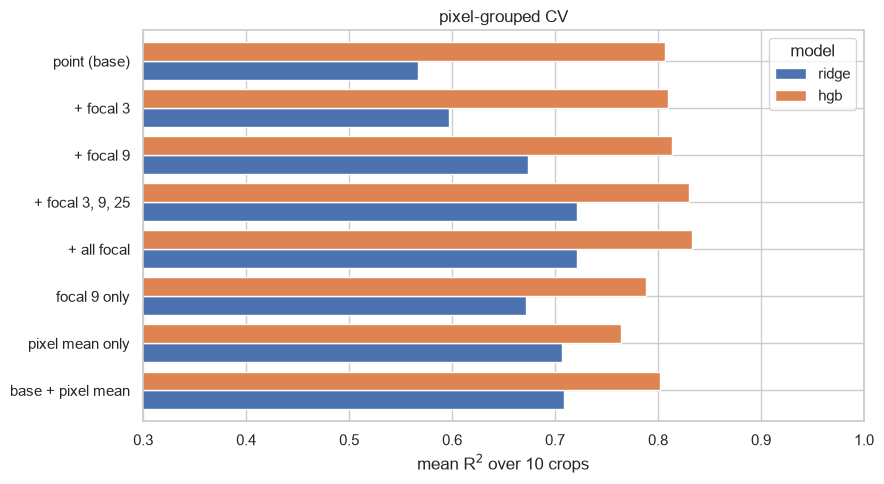

In [5]:
fig, ax = plt.subplots(figsize=(9, 5))
tbl["pixel"][MODELS].iloc[::-1].plot.barh(ax=ax, width=0.8)
ax.set(title="pixel-grouped CV", xlabel="mean R$^2$ over 10 crops", ylabel="", xlim=(0.3, 1))
plt.tight_layout()
E.save_fig(fig, "m04_context")
plt.show()

## 2. Which neighbourhood scale helps most?
GAEZ pixels are ~9 km wide, so a 9 km window should match the target's own support.

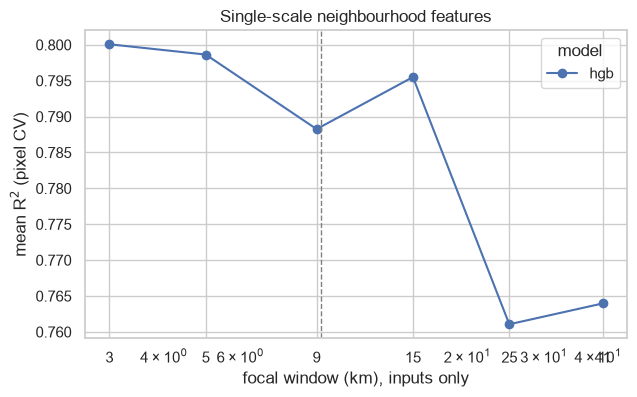

model,hgb
window (km),
3,0.800
5,0.799
9,0.788
15,0.796
25,0.761
41,0.764


In [6]:
scales = {}
for k in SIZES:
    r, _ = E.run_grid(dfc, targets, ["hgb"], ["pixel"], columns=focal(k), n_repeats=2, verbose=False)
    scales[k] = r.groupby("model")["r2"].mean()
scales = pd.DataFrame(scales).T
scales.index.name = "window (km)"
E.save_table(scales.round(4), "m04_focal_scale", index=True)
fig, ax = plt.subplots(figsize=(7, 4))
scales.plot(ax=ax, marker="o")
ax.axvline(9.2, color="grey", ls="--", lw=1)
ax.set(xscale="log", xlabel="focal window (km), inputs only", ylabel="mean R$^2$ (pixel CV)", title="Single-scale neighbourhood features")
ax.set_xticks(list(SIZES), [str(s) for s in SIZES])
E.save_fig(fig, "m04_focal_scale")
plt.show()
scales.round(3)

## 3. Train at the source resolution (one row per native GAEZ pixel)

In [7]:
pix = dfc.groupby("pix").agg(pix_row=("pix_row", "first"), pix_col=("pix_col", "first"), n_cells=("grid_id", "size"),
                             **{c: (c, "mean") for c in base}, **{f"gaez_index_{c}": (f"gaez_index_{c}", "mean") for c in E.CROPS})
pix = pix.reset_index()
pix["row"] = pix["pix_row"] - pix["pix_row"].min()
pix["col"] = pix["pix_col"] - pix["pix_col"].min()
print(pix.shape, "pixels; cells per pixel: min", pix.n_cells.min(), "median", int(pix.n_cells.median()), "max", pix.n_cells.max())

ptargets = {c: pix[f"gaez_index_{c}"].to_numpy() for c in E.CROPS}
PMODELS = ["ridge", "knn", "et", "hgb"]
pres, _ = E.run_grid(pix, ptargets, PMODELS, ["random", "block2", "block3"], columns=base, n_repeats=5, verbose=False)
E.save_table(pres, "m04_pixel_level_raw")
ptab = pres.groupby(["model", "scheme"])["r2"].mean().unstack("scheme")[["random", "block2", "block3"]]
ptab.round(3)

(164, 30) pixels; cells per pixel: min 1 median 79 max 100


scheme,random,block2,block3
model,,,
et,0.619,0.552,0.535
hgb,0.539,0.455,0.419
knn,0.482,0.431,0.405
ridge,0.514,0.451,0.433


In [8]:
# Cell-level models, predictions averaged back to pixels, scored with equal weight per pixel (same footing as above).
from sklearn.metrics import r2_score
pix_truth = {c: df.groupby("pix")[f"gaez_index_{c}"].mean() for c in E.CROPS}
rows = []
for fset in ["point (base)", "+ focal 9", "+ all focal"]:
    for (m, c, s, r), pred in keep[fset].items():
        if s != "pixel":
            continue
        agg = pd.Series(pred).groupby(df["pix"].to_numpy()).mean()
        rows.append({"feature_set": fset, "model": m, "crop": c, "repeat": r, "r2_pixel_level": r2_score(pix_truth[c].loc[agg.index], agg)})
agg_df = pd.DataFrame(rows)
cell_vs_pix = agg_df.groupby(["feature_set", "model"])["r2_pixel_level"].mean().unstack("model")
cell_vs_pix.round(3)

model,hgb,ridge
feature_set,,
+ all focal,0.729,0.591
+ focal 9,0.680,0.546
point (base),0.673,0.458


In [9]:
ptab_best = ptab.max(axis=1).sort_values(ascending=False)
print("Pixel-level training (164 rows), best CV scheme per model - mean R2 over crops:")
print(pd.concat([ptab, ptab_best.rename("best")], axis=1).round(3).to_string())
print()
print("Cell-level training, scored at pixel level (pixel CV):")
print(cell_vs_pix.round(3).to_string())

Pixel-level training (164 rows), best CV scheme per model - mean R2 over crops:
       random  block2  block3   best
model                               
et      0.619   0.552   0.535  0.619
hgb     0.539   0.455   0.419  0.539
knn     0.482   0.431   0.405  0.482
ridge   0.514   0.451   0.433  0.514

Cell-level training, scored at pixel level (pixel CV):
model           hgb  ridge
feature_set               
+ all focal   0.729  0.591
+ focal 9     0.680  0.546
point (base)  0.673  0.458
